Importing the Libraries

In [1]:
# Topic: Libraries We Need
# pandas  -> to work with tables
# numpy   -> for maths
# matplotlib and seaborn -> to draw graphs
# sklearn -> to build the machine learning model

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Creating the Dataset (Practice Hours and Typing Speed)

In [2]:
# Topic: Our First Dataset
# We make a small dataset: how many hours a student practised typing
# and the typing speed (words per minute) they reached.
# We save it as a CSV so we can load it like a real dataset.

np.random.seed(10)
hours = np.round(np.random.uniform(1, 10, 30), 1)
speed = np.round(18 + 6.5 * hours + np.random.normal(0, 3, 30))   # speed grows with hours

pd.DataFrame({"Hours": hours, "Speed": speed}).to_csv("typing.csv", index=False)

df = pd.read_csv("typing.csv")
print(df.head())

   Hours  Speed
0    7.9   70.0
1    1.2   30.0
2    6.7   61.0
3    7.7   70.0
4    5.5   53.0


Exploratory Data Analysis

In [3]:
# Topic: Exploring the Data
# Before building a model, we look at the data first

print("Shape (rows, columns):", df.shape)
print(df.describe().round(2))

Shape (rows, columns): (30, 2)
       Hours  Speed
count  30.00   30.0
mean    5.60   54.6
std     2.39   14.7
min     1.00   28.0
25%     3.80   42.0
50%     6.15   58.0
75%     7.35   65.0
max     9.60   79.0


Plotting the Data

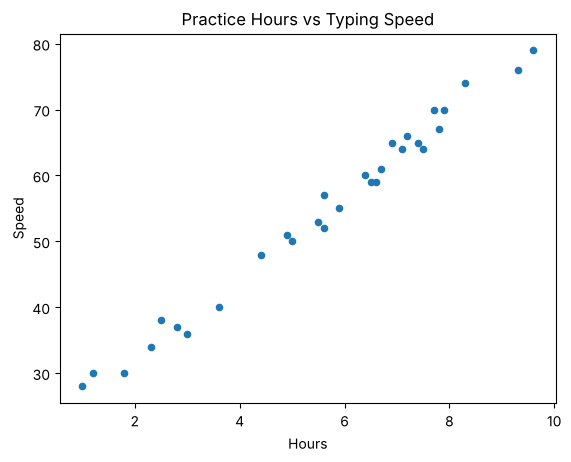

In [4]:
# Topic: Scatter Plot
# A scatter plot shows if the two columns move together

df.plot.scatter(x="Hours", y="Speed", title="Practice Hours vs Typing Speed")
plt.show()
# The points rise from left to right, so a straight line should fit well

Checking the Correlation

In [5]:
# Topic: Correlation
# A value close to 1 means a strong positive relationship

print(df.corr().round(3))

       Hours  Speed
Hours  1.000  0.993
Speed  0.993  1.000


Linear Regression Theory

In [6]:
# Topic: How Linear Regression Works
# Linear regression draws the best straight line through the points:
#
#     y = a * x + b
#
# x -> input (Hours)
# y -> output we want to predict (Speed)
# a -> slope: how much y grows when x goes up by 1
# b -> intercept: the value of y when x is 0
#
# The "best" line is the one where the total squared distance
# between the points and the line is the smallest.

# Example with a made-up line: a = 6, b = 20
a, b = 6, 20
for x in [2, 5, 8]:
    print(f"If Hours = {x}, the line predicts Speed = {a * x + b}")

If Hours = 2, the line predicts Speed = 32
If Hours = 5, the line predicts Speed = 50
If Hours = 8, the line predicts Speed = 68


Data Preprocessing

In [7]:
# Topic: Preparing the Data
# X (input) must be 2-D for sklearn, so we reshape it.
# y (output) can stay 1-D.

X = df["Hours"].values.reshape(-1, 1)
y = df["Speed"].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30, 1)
y shape: (30,)


Splitting into Train and Test Sets

In [8]:
# Topic: train_test_split()
# We train the model on 80% of the data and test it on the other 20%.
# random_state fixes the split so we get the same result every time.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 24
Testing rows: 6


Training a Linear Regression Model

In [9]:
# Topic: Training the Model
# fit() makes the model learn the best slope and intercept from the training data

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept (b):", round(model.intercept_, 2))
print("Slope (a):", round(model.coef_[0], 2))
print(f"So the learned line is: Speed = {model.coef_[0]:.2f} * Hours + {model.intercept_:.2f}")

Intercept (b): 20.38
Slope (a): 6.11
So the learned line is: Speed = 6.11 * Hours + 20.38


Drawing the Best Fit Line

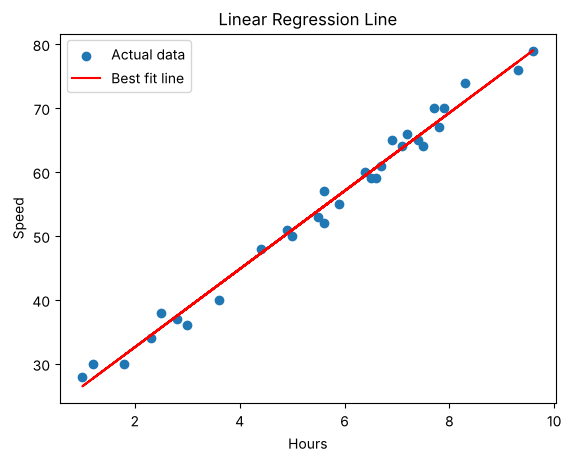

In [10]:
# Topic: Seeing the Line on the Graph

plt.scatter(X, y, label="Actual data")
plt.plot(X, model.predict(X), color="red", label="Best fit line")
plt.xlabel("Hours")
plt.ylabel("Speed")
plt.title("Linear Regression Line")
plt.legend()
plt.show()

Making a Single Prediction

In [11]:
# Topic: Predicting One Value
# What typing speed can we expect after 7.5 hours of practice?

new_hours = [[7.5]]
predicted = model.predict(new_hours)
print("Predicted speed after 7.5 hours:", round(predicted[0], 1), "words per minute")

Predicted speed after 7.5 hours: 66.2 words per minute


Making Predictions on the Test Set

In [12]:
# Topic: Predicting the Test Data
# We compare the real values with what the model predicted

y_pred = model.predict(X_test)

results = pd.DataFrame({"Actual": y_test, "Predicted": y_pred.round(1)})
print(results)

   Actual  Predicted
0    57.0       54.6
1    59.0       60.1
2    64.0       63.8
3    40.0       42.4
4    38.0       35.7
5    30.0       31.4


Evaluating the Model

In [13]:
# Topic: Error Metrics
# MAE  -> average size of the mistakes
# MSE  -> average of the squared mistakes (big mistakes count more)
# RMSE -> square root of MSE, in the same unit as the data
# Smaller values mean a better model.

from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

Mean Absolute Error (MAE): 1.64
Mean Squared Error (MSE): 3.35
Root Mean Squared Error (RMSE): 1.83


Multiple Linear Regression

In [14]:
# Topic: Multiple Linear Regression
# Simple regression uses one input. Multiple regression uses many inputs:
#
#     y = a1*x1 + a2*x2 + a3*x3 + ... + b
#
# Now we predict a house price using four inputs:
# Area, Rooms, Age of the house and Distance from the city center.

np.random.seed(5)
n = 60
area = np.random.randint(500, 3000, n)          # square feet
rooms = np.random.randint(1, 6, n)
age = np.random.randint(0, 40, n)               # years
distance = np.round(np.random.uniform(1, 25, n), 1)   # km

# Price in thousand rupees: bigger and newer houses near the city cost more
price = (8 * area + 900 * rooms - 120 * age - 250 * distance
         + 2000 + np.random.normal(0, 1500, n)).round()

houses = pd.DataFrame({"Area": area, "Rooms": rooms, "Age": age,
                       "Distance": distance, "Price": price})
houses.to_csv("houses.csv", index=False)

houses = pd.read_csv("houses.csv")
print(houses.head())

   Area  Rooms  Age  Distance    Price
0  2754      4    7       5.7  25059.0
1  2225      1   12      20.6  13242.0
2  1924      1   20      20.4  10625.0
3  2621      5    8      15.1  22402.0
4  1532      5   10      23.0  13382.0


Exploratory Data Analysis of the Houses Data

In [15]:
# Topic: Looking at the New Data

print("Shape:", houses.shape)
print(houses.describe().round(1).T)   # .T flips rows and columns so it is easier to read

Shape: (60, 5)
          count     mean     std    min     25%      50%      75%      max
Area       60.0   1612.4   748.9  514.0   884.5   1509.0   2274.0   2959.0
Rooms      60.0      3.1     1.5    1.0     2.0      3.0      4.2      5.0
Age        60.0     17.6    11.9    0.0     7.8     18.5     27.0     39.0
Distance   60.0     13.8     6.1    1.7     8.6     14.4     17.6     24.9
Price      60.0  12382.0  6586.6 -665.0  7204.5  12424.5  17217.5  25059.0


Plotting Each Input against Price

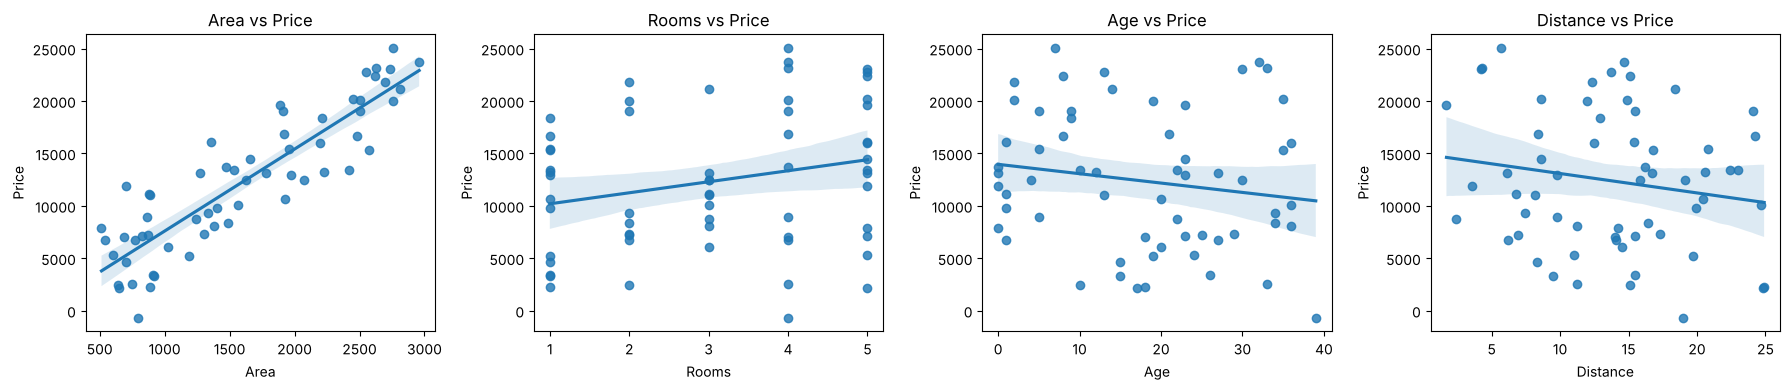

In [16]:
# Topic: Regression Plots
# regplot() draws the points and a trend line for each input

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["Area", "Rooms", "Age", "Distance"]):
    sns.regplot(x=col, y="Price", data=houses, ax=ax)
    ax.set_title(f"{col} vs Price")
plt.tight_layout()
plt.show()

Correlation Heatmap

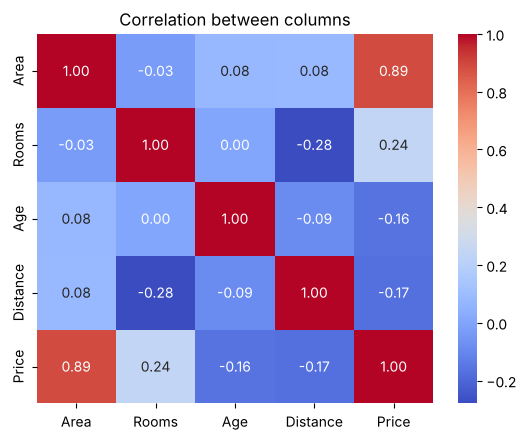

In [17]:
# Topic: Heatmap of Correlations
# Colors show how strongly each pair of columns is related

sns.heatmap(houses.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between columns")
plt.show()

Preparing the Data

In [18]:
# Topic: Choosing Inputs and Output, then Splitting

X = houses[["Area", "Rooms", "Age", "Distance"]]
y = houses["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", X_train.shape[0], "| Testing rows:", X_test.shape[0])

Training rows: 48 | Testing rows: 12


Training the Multivariate Model

In [19]:
# Topic: Training with Many Inputs
# The model learns one coefficient (slope) for each input

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

print("Intercept:", round(multi_model.intercept_, 2))

coefs = pd.DataFrame({"Coefficient": multi_model.coef_.round(2)}, index=X.columns)
print(coefs)

# How to read it: if Area goes up by 1 sq ft (and everything else stays the same),
# the price changes by the Area coefficient. A negative value lowers the price.

Intercept: 1894.38
          Coefficient
Area             8.37
Rooms          934.04
Age           -144.28
Distance      -244.09


Making Predictions with the Multivariate Model

In [20]:
# Topic: Predicting House Prices

y_pred = multi_model.predict(X_test)

compare = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred.round()})
print(compare)

# Predict the price of one new house
new_house = pd.DataFrame({"Area": [1800], "Rooms": [3], "Age": [5], "Distance": [6.0]})
print("\nPredicted price of the new house:", round(multi_model.predict(new_house)[0]), "thousand rupees")

     Actual  Predicted
0   25059.0    26289.0
1    8760.0    11319.0
2   14462.0    15038.0
3    7310.0     6249.0
4   20090.0    22671.0
5   19037.0    17143.0
6    6782.0     4834.0
7    6102.0     6879.0
8   11912.0    11589.0
9    3359.0     2896.0
10  16047.0    13990.0
11   8351.0     7296.0

Predicted price of the new house: 17582 thousand rupees


Evaluating the Multivariate Model

In [21]:
# Topic: Errors and R² Score
# R² tells how much of the change in price the model explains.
# 1.0 is perfect; closer to 1 is better.

from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE : {mae:.2f}")
print(f"MSE : {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}")

# R² calculated by hand: 1 - (error of model / error of just using the mean)
r2_manual = 1 - ((y_test - y_pred) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum()
print(f"R² by hand: {r2_manual:.3f}")

MAE : 1376.91
MSE : 2485557.05
RMSE: 1576.56
R²  : 0.939
R² by hand: 0.939


Checking for Overfitting

In [22]:
# Topic: Train Score vs Test Score
# If the train score is much higher than the test score, the model has "memorized"
# the training data (overfitting). Close scores mean the model generalizes well.

train_score = multi_model.score(X_train, y_train)
test_score = multi_model.score(X_test, y_test)

print(f"R² on training data: {train_score:.3f}")
print(f"R² on testing data : {test_score:.3f}")

R² on training data: 0.962
R² on testing data : 0.939


Conclusion

In [23]:
# Topic: Summary
# 1. Simple linear regression: one input (Hours) to predict one output (Speed)
# 2. Multiple linear regression: many inputs (Area, Rooms, Age, Distance) to predict Price
# 3. We checked the models with MAE, MSE, RMSE and R²

print("Simple model line   : Speed = %.2f * Hours + %.2f" % (model.coef_[0], model.intercept_))
print("Multiple model R² (test): %.3f" % multi_model.score(X_test, y_test))

Simple model line   : Speed = 6.11 * Hours + 20.38
Multiple model R² (test): 0.939
